# M3 — Decision Tree and Random Forest (QBUS6810 Group Assignment)

**Scope.** Tree-based regression models for Section 3 (3b model choices, 3e tuning and complexity control), validation-stage diagnostics that prepare 4a/4b, and a guarded final-test routine for 4a. Following the group rules, every model family is selected separately under the three error-weighting scenarios (2:1, 1:1, 1:2), and results are reported with MSE, R², MAE and WAE in the same table format as the linear-model results.

**Inputs (read-only).** `data/split/train.csv`, `data/split/validation.csv` and their `*_membership.csv` files produced by `assignment_6810.ipynb`; `data/sales.csv` and `data/properties_2022.csv` for alignment checks, dates and township codes. No shared file is modified.

**Outputs.** Everything is written to `data/result/trees/` (tables) and `data/result/trees/figures/` (figures).

**Required packages.** Same environment as the main notebook (Python 3.9.13, numpy 1.21.5, pandas 1.4.4, scikit-learn 1.0.2, matplotlib 3.5.2). Only APIs available in scikit-learn 1.0.2 are used.

**How to run.** Open this notebook from the project folder (next to `data/`) and run all cells in order (Restart & Run All). All paths are relative and `random_state=42` is fixed. The random-forest grid is the slowest step (roughly 5–10 minutes on a 12-thread laptop; about 35 minutes on 2 cores). The 2025 test set is not loaded unless `RUN_TEST = True`.

## 0. Settings

The first block holds the switches that depend on open group decisions (target scale, time trend, dropped columns, final-test window). Changing a switch and re-running the notebook regenerates every table and figure; no other code needs editing.

In [1]:
import gc
import hashlib
import json
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

# ---- Switches that depend on open group decisions ----
TARGET = "dollar"                 # "dollar": fit sale_price; "log": fit log1p(sale_price), back-transform with expm1
ADD_TIME_TREND = False            # True adds months since January 2023 (from membership sale dates)
DROP_COLS = ["loc_env_airport_noise_dnl"]   # collapsed to numerical noise in the current split export
RUN_TEST = False                  # keep False until the final model and procedure are frozen
FINAL_FIT_WINDOW = "train+validation"       # data used to refit before the 2025 test: "train+validation" or "train"

# ---- Fixed settings ----
RANDOM_STATE = 42
N_JOBS = -1
DT_GRID = {
    "max_depth": [2, 4, 6, 8, 10, 12, 15, 20, None],
    "min_samples_leaf": [1, 10, 50, 200],
}
RF_PATH_CONFIG = {"max_features": 0.33, "min_samples_leaf": 3}
RF_N_ESTIMATORS_PATH = [25, 50, 100, 200, 300]
RF_GRID = {
    "max_features": [0.2, 0.33, 0.5, 0.8],
    "min_samples_leaf": [1, 3, 10, 30],
}
PERMUTATION_SAMPLE = 5000
PERMUTATION_REPEATS = 3

DATA_DIR = Path("data")
SPLIT_DIR = DATA_DIR / "split"
OUT_DIR = DATA_DIR / "result" / "trees"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SCENARIOS = {
    "WAE_2_1": ("Main - Overvaluation Priority (2:1)", 2, 1),
    "WAE_1_1": ("Alternative - Equal Priority (1:1)", 1, 1),
    "WAE_1_2": ("Alternative - Undervaluation Priority (1:2)", 1, 2),
}
MAIN_METRIC = "WAE_2_1"

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print(f"TARGET={TARGET}, ADD_TIME_TREND={ADD_TIME_TREND}, DROP_COLS={DROP_COLS}, "
      f"RUN_TEST={RUN_TEST}, FINAL_FIT_WINDOW={FINAL_FIT_WINDOW}")

Python 3.13.2 | numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.8.0 | matplotlib 3.10.3
TARGET=dollar, ADD_TIME_TREND=False, DROP_COLS=['loc_env_airport_noise_dnl'], RUN_TEST=False, FINAL_FIT_WINDOW=train+validation


## 1. Load the frozen training and validation data

The official split files are checked against `manifest.json`, their row order is checked against the membership files, and the stored prices are checked against `sales.csv`. Only 2023–2024 sale prices are read from `sales.csv`.

In [2]:
def sha256_line_ending_variants(path):
    # The manifest was written from Windows (CRLF) copies; Git or a GitHub zip may deliver LF.
    # Accept either line ending so the check verifies content, not the platform.
    raw = Path(path).read_bytes()
    lf = raw.replace(b"\r\n", b"\n")
    crlf = lf.replace(b"\n", b"\r\n")
    return {hashlib.sha256(variant).hexdigest() for variant in (raw, lf, crlf)}


manifest = json.loads((SPLIT_DIR / "manifest.json").read_text(encoding="utf-8"))


def load_split(name):
    split_info = manifest["splits"][name]
    member_info = manifest["membership"][name]
    data_path = SPLIT_DIR / split_info["file"]
    member_path = SPLIT_DIR / member_info["file"]
    assert split_info["sha256"] in sha256_line_ending_variants(data_path), f"{name}.csv differs from manifest"
    assert member_info["sha256"] in sha256_line_ending_variants(member_path), f"{name} membership differs from manifest"
    frame = pd.read_csv(data_path)
    members = pd.read_csv(
        member_path,
        dtype={"transaction_id": str, "property_id": str},
        parse_dates=["sale_date"],
    )
    assert len(frame) == len(members) == split_info["rows"]
    assert np.allclose(np.log1p(frame["sale_price"]), frame["log_sale_price"])
    return frame, members


train_raw, train_ids = load_split("train")
val_raw, val_ids = load_split("validation")

# Row-order check against the original sales file (2023-2024 prices only).
dev_sales = pd.read_csv(
    DATA_DIR / "sales.csv",
    usecols=["transaction_id", "sale_date", "sale_price"],
    dtype={"transaction_id": str},
    parse_dates=["sale_date"],
)
dev_sales = dev_sales.loc[dev_sales["sale_date"] < "2025-01-01", ["transaction_id", "sale_price"]]
for name, frame, members in [("train", train_raw, train_ids), ("validation", val_raw, val_ids)]:
    matched = members[["transaction_id"]].merge(dev_sales, on="transaction_id", how="left", validate="one_to_one")
    assert np.allclose(matched["sale_price"].to_numpy(), frame["sale_price"].to_numpy()), f"{name} order mismatch"
del dev_sales

print(f"Train:      {len(train_raw):,} sales, {train_ids['sale_date'].min().date()} to {train_ids['sale_date'].max().date()}")
print(f"Validation: {len(val_raw):,} sales, {val_ids['sale_date'].min().date()} to {val_ids['sale_date'].max().date()}")
print("Checksums, membership order and sale prices verified.")

Train:      54,853 sales, 2023-01-01 to 2024-06-30
Validation: 18,132 sales, 2024-07-01 to 2024-12-31
Checksums, membership order and sale prices verified.


## 2. Predictors, target scale and evaluation functions

Predictors are all columns of the official split except `sale_price`, `log_sale_price` and `DROP_COLS`. Trees do not need the scaling already applied in the split files, but scaling is monotone and does not change tree splits. The metric functions reproduce the group's linear-model code exactly, so results can be merged into one table.

In [3]:
TARGET_COLUMNS = ["sale_price", "log_sale_price"]


def build_features(frame, members):
    drop = TARGET_COLUMNS + [column for column in DROP_COLS if column in frame.columns]
    features = frame.drop(columns=drop)
    if ADD_TIME_TREND:
        dates = members["sale_date"]
        features = features.assign(
            months_since_2023_01=((dates.dt.year - 2023) * 12 + dates.dt.month - 1).to_numpy()
        )
    return features


def to_fit_scale(prices):
    return np.log1p(prices) if TARGET == "log" else prices


def to_dollars(predictions):
    return np.expm1(predictions) if TARGET == "log" else predictions


X_train = build_features(train_raw, train_ids)
X_val = build_features(val_raw, val_ids)
assert X_train.columns.tolist() == X_val.columns.tolist()
assert not X_train.isna().any().any() and not X_val.isna().any().any()
y_train = train_raw["sale_price"].to_numpy(dtype=float)
y_val = val_raw["sale_price"].to_numpy(dtype=float)
y_train_fit = to_fit_scale(y_train)

FEATURE_SET_LABEL = f"Official split CSV ({X_train.shape[1]} predictors)"
print(f"Feature set: {FEATURE_SET_LABEL}")
print(f"Dropped: {[c for c in DROP_COLS if c in train_raw.columns]}")
print(f"Time trend added: {ADD_TIME_TREND}; target scale for fitting: {TARGET}")


def weighted_absolute_error(y_true, y_pred, overvaluation_weight, undervaluation_weight):
    y_true_array = np.asarray(y_true, dtype=float)
    y_pred_array = np.asarray(y_pred, dtype=float)
    assert y_true_array.shape == y_pred_array.shape
    assert np.isfinite(y_true_array).all() and np.isfinite(y_pred_array).all()
    prediction_error = y_pred_array - y_true_array
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return float(np.mean(np.abs(prediction_error) * direction_weights))


def evaluate_regression_predictions(y_true, y_pred):
    metrics = {
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }
    assert np.isclose(metrics["WAE_1_1"], metrics["MAE"], rtol=1e-12, atol=1e-8)
    return metrics


def assessment_ratio_statistics(y_true, y_pred):
    # IAAO-style ratio statistics: ratio = estimate / sale price.
    ratio = np.asarray(y_pred, dtype=float) / np.asarray(y_true, dtype=float)
    median_ratio = np.median(ratio)
    cod = 100 * np.mean(np.abs(ratio - median_ratio)) / median_ratio
    prd = np.mean(ratio) / (np.sum(y_pred) / np.sum(y_true))
    return {"median_ratio": median_ratio, "COD": cod, "PRD": prd}


# Manual checks of error direction and the denominator (same as the linear-model notebook).
manual_actual = np.array([100.0, 100.0, 100.0])
manual_prediction = np.array([120.0, 70.0, 100.0])
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 2, 1), 70 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 1), 50 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 2), 80 / 3)
print("WAE manual checks passed.")

Feature set: Official split CSV (208 predictors)
Dropped: ['loc_env_airport_noise_dnl']
Time trend added: False; target scale for fitting: dollar
WAE manual checks passed.


## 3. Reference: Global Mean baseline on the same rows

Recomputed here only to confirm that this notebook scores exactly the same validation rows as the linear-model results.

In [4]:
baseline_prediction = np.full(len(y_val), y_train.mean())
baseline_metrics = evaluate_regression_predictions(y_val, baseline_prediction)
print(pd.Series(baseline_metrics).to_string(float_format=lambda v: f"{v:,.4f}"))

recorded_baseline_path = DATA_DIR / "result" / "baseline" / "global_mean_baseline_metrics.csv"
if recorded_baseline_path.exists():
    recorded = pd.read_csv(recorded_baseline_path, encoding="utf-8-sig")
    same = np.isclose(recorded["MAE ($)"].iloc[0], baseline_metrics["MAE"])
    print(f"\nMatches the recorded group baseline MAE: {same}")

WAE_2_1           342,381.8231
WAE_1_1           238,599.6175
WAE_1_2           373,417.0295
MSE       191,693,119,024.9673
R2                     -0.0050
MAE               238,599.6175

Matches the recorded group baseline MAE: True


## 4. Decision Tree

A single regression tree is the interpretable member of the tree family and shows the bias–variance trade-off directly. Complexity is controlled with `max_depth` and `min_samples_leaf`. Every configuration is scored on validation; training error is also recorded to show overfitting.

In [5]:
run_rows = []
validation_predictions = {}


def configuration_text(params):
    return ", ".join(f"{key}={value}" for key, value in params.items())


def record_run(run_id, family, params, model, fit_seconds, oob_mae=np.nan):
    val_pred = to_dollars(model.predict(X_val))
    train_pred = to_dollars(model.predict(X_train))
    metrics = evaluate_regression_predictions(y_val, val_pred)
    validation_predictions[run_id] = val_pred
    row = {
        "run_id": run_id,
        "model_family": family,
        "feature_set": FEATURE_SET_LABEL,
        "configuration": configuration_text(params),
        "max_depth": str(params.get("max_depth", "")),
        "min_samples_leaf": params.get("min_samples_leaf", np.nan),
        "max_features": params.get("max_features", np.nan),
        "n_estimators": params.get("n_estimators", np.nan),
        **metrics,
        "train_MAE": mean_absolute_error(y_train, train_pred),
        "train_R2": r2_score(y_train, train_pred),
        "OOB_MAE": oob_mae,
        "fit_seconds": fit_seconds,
        "target_scale": TARGET,
        "time_trend": ADD_TIME_TREND,
        "dropped_columns": ";".join(DROP_COLS),
    }
    run_rows.append(row)
    return row


run_number = 0
for depth in DT_GRID["max_depth"]:
    for leaf in DT_GRID["min_samples_leaf"]:
        run_number += 1
        params = {"max_depth": depth, "min_samples_leaf": leaf}
        start = time.perf_counter()
        tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **params).fit(X_train, y_train_fit)
        row = record_run(f"T{run_number:03d}", "Decision Tree", params, tree, time.perf_counter() - start)
        del tree

dt_results = pd.DataFrame([row for row in run_rows if row["model_family"] == "Decision Tree"])
print(f"Decision Tree configurations evaluated: {len(dt_results)}")
print(
    dt_results.sort_values(MAIN_METRIC)
    .head(10)[["run_id", "configuration", "train_MAE", "MAE", "WAE_2_1", "WAE_1_2", "R2"]]
    .to_string(index=False, float_format=lambda v: f"{v:,.3f}")
)

Decision Tree configurations evaluated: 36
run_id                       configuration   train_MAE         MAE     WAE_2_1     WAE_1_2    R2
  T018   max_depth=10, min_samples_leaf=10  93,020.292 115,419.378 160,666.563 185,591.572 0.692
  T023   max_depth=12, min_samples_leaf=50  97,885.486 115,692.170 161,709.484 185,367.027 0.675
  T019   max_depth=10, min_samples_leaf=50  99,884.134 115,648.088 161,736.548 185,207.717 0.675
  T027   max_depth=15, min_samples_leaf=50  96,899.593 115,935.232 161,949.166 185,856.531 0.674
  T035 max_depth=None, min_samples_leaf=50  96,576.859 116,031.025 162,195.202 185,897.873 0.674
  T031   max_depth=20, min_samples_leaf=50  96,585.160 116,045.381 162,198.048 185,938.096 0.674
  T014    max_depth=8, min_samples_leaf=10 101,223.045 116,173.072 162,222.984 186,296.231 0.692
  T015    max_depth=8, min_samples_leaf=50 103,902.387 116,809.152 163,177.141 187,250.315 0.671
  T022   max_depth=12, min_samples_leaf=10  86,315.879 117,534.257 163,724.425 188,8

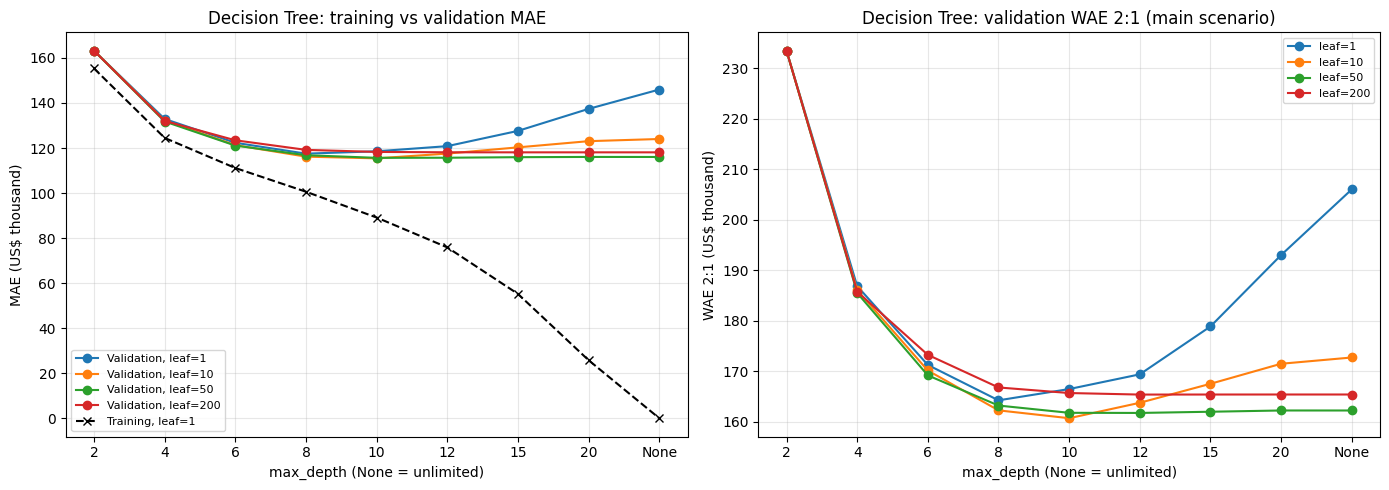

In [6]:
depth_labels = [str(depth) for depth in DT_GRID["max_depth"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for leaf in DT_GRID["min_samples_leaf"]:
    subset = dt_results.loc[dt_results["min_samples_leaf"] == leaf].set_index("max_depth").loc[depth_labels]
    axes[0].plot(depth_labels, subset["MAE"] / 1e3, marker="o", label=f"Validation, leaf={leaf}")
    axes[1].plot(depth_labels, subset["WAE_2_1"] / 1e3, marker="o", label=f"leaf={leaf}")
leaf1 = dt_results.loc[dt_results["min_samples_leaf"] == 1].set_index("max_depth").loc[depth_labels]
axes[0].plot(depth_labels, leaf1["train_MAE"] / 1e3, color="black", linestyle="--", marker="x", label="Training, leaf=1")
axes[0].set_title("Decision Tree: training vs validation MAE")
axes[0].set_ylabel("MAE (US$ thousand)")
axes[1].set_title("Decision Tree: validation WAE 2:1 (main scenario)")
axes[1].set_ylabel("WAE 2:1 (US$ thousand)")
for axis in axes:
    axis.set_xlabel("max_depth (None = unlimited)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T1_decision_tree_complexity.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Random Forest

### 5a. Number of trees

The number of trees is not a complexity parameter in the usual sense: more trees reduce variance without increasing overfitting, but cost time. The forest is grown with `warm_start` and the smallest size whose validation MAE is within 0.5% of the best value on the path is used for the grid. Out-of-bag (OOB) error is shown alongside validation error; OOB error is a within-period estimate, so the gap between them indicates how much accuracy is lost when predicting a later period.

 n_estimators  validation_MAE  validation_WAE_2_1  OOB_MAE  incremental_fit_seconds
           25       103,385.5           142,935.6 99,657.7                      5.6
           50       102,113.5           140,952.2 96,645.0                      6.8
          100       101,814.7           140,563.2 95,076.8                     13.8
          200       101,477.3           140,167.5 94,385.2                     18.9
          300       101,258.3           139,896.1 94,116.9                     29.4

Selected n_estimators for the grid: 200


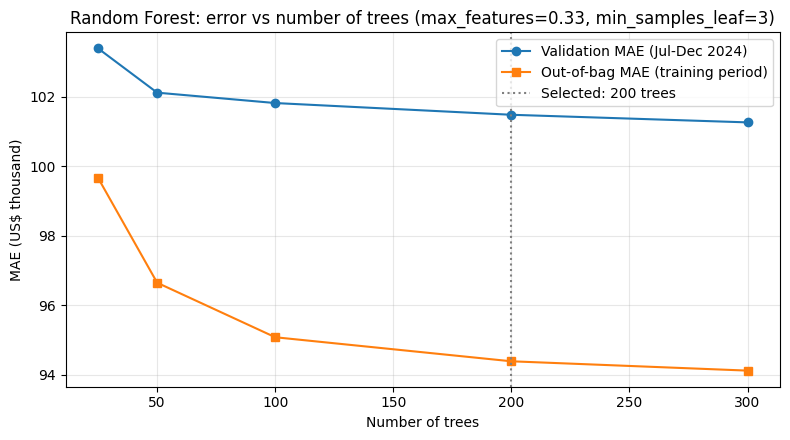

In [7]:
import warnings

path_rows = []
forest_path = RandomForestRegressor(
    n_estimators=RF_N_ESTIMATORS_PATH[0],
    warm_start=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    **RF_PATH_CONFIG,
)
for n_trees in RF_N_ESTIMATORS_PATH:
    forest_path.set_params(n_estimators=n_trees)
    start = time.perf_counter()
    with warnings.catch_warnings():
        # With 25 trees a handful of rows are never out of bag; they are excluded below.
        warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
        forest_path.fit(X_train, y_train_fit)
    elapsed = time.perf_counter() - start
    oob_pred = to_dollars(forest_path.oob_prediction_)
    has_oob = forest_path.oob_prediction_ != 0          # rows never left out of bag are returned as 0
    val_pred = to_dollars(forest_path.predict(X_val))
    path_rows.append({
        "n_estimators": n_trees,
        "validation_MAE": mean_absolute_error(y_val, val_pred),
        "validation_WAE_2_1": weighted_absolute_error(y_val, val_pred, 2, 1),
        "OOB_MAE": mean_absolute_error(y_train[has_oob], oob_pred[has_oob]),
        "incremental_fit_seconds": elapsed,
    })
del forest_path
gc.collect()

rf_path = pd.DataFrame(path_rows)
best_path_mae = rf_path["validation_MAE"].min()
RF_N_ESTIMATORS = int(rf_path.loc[rf_path["validation_MAE"] <= 1.005 * best_path_mae, "n_estimators"].min())
rf_path.to_csv(OUT_DIR / "rf_n_estimators_path.csv", index=False)
print(rf_path.to_string(index=False, float_format=lambda v: f"{v:,.1f}"))
print(f"\nSelected n_estimators for the grid: {RF_N_ESTIMATORS}")

fig, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(rf_path["n_estimators"], rf_path["validation_MAE"] / 1e3, marker="o", label="Validation MAE (Jul-Dec 2024)")
axis.plot(rf_path["n_estimators"], rf_path["OOB_MAE"] / 1e3, marker="s", label="Out-of-bag MAE (training period)")
axis.axvline(RF_N_ESTIMATORS, color="grey", linestyle=":", label=f"Selected: {RF_N_ESTIMATORS} trees")
axis.set_xlabel("Number of trees")
axis.set_ylabel("MAE (US$ thousand)")
axis.set_title(f"Random Forest: error vs number of trees ({configuration_text(RF_PATH_CONFIG)})")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "T2_rf_n_estimators.png", dpi=150, bbox_inches="tight")
plt.show()

### 5b. Complexity grid

`min_samples_leaf` limits how finely each tree fits the training data (larger = simpler trees). `max_features` sets the share of predictors considered at each split; smaller values decorrelate the trees and add randomness. Each configuration is fitted once and scored under all three WAE scenarios with fixed predictions.

In [8]:
grid_start = time.perf_counter()
run_number = 0
for max_features in RF_GRID["max_features"]:
    for leaf in RF_GRID["min_samples_leaf"]:
        run_number += 1
        params = {"n_estimators": RF_N_ESTIMATORS, "max_features": max_features, "min_samples_leaf": leaf}
        start = time.perf_counter()
        forest = RandomForestRegressor(oob_score=True, random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
        forest.fit(X_train, y_train_fit)
        fit_seconds = time.perf_counter() - start
        has_oob = forest.oob_prediction_ != 0
        oob_mae = mean_absolute_error(y_train[has_oob], to_dollars(forest.oob_prediction_)[has_oob])
        row = record_run(f"R{run_number:03d}", "Random Forest", params, forest, fit_seconds, oob_mae)
        print(f"{row['run_id']} {row['configuration']}: val MAE {row['MAE']:,.0f}, "
              f"WAE 2:1 {row['WAE_2_1']:,.0f}, OOB MAE {oob_mae:,.0f} ({fit_seconds:.0f}s)")
        del forest
        gc.collect()

rf_results = pd.DataFrame([row for row in run_rows if row["model_family"] == "Random Forest"])
print(f"\nRandom Forest grid finished in {(time.perf_counter() - grid_start) / 60:.1f} minutes.")

R001 n_estimators=200, max_features=0.2, min_samples_leaf=1: val MAE 101,967, WAE 2:1 141,697, OOB MAE 95,388 (21s)
R002 n_estimators=200, max_features=0.2, min_samples_leaf=3: val MAE 101,051, WAE 2:1 139,417, OOB MAE 94,327 (11s)
R003 n_estimators=200, max_features=0.2, min_samples_leaf=10: val MAE 101,021, WAE 2:1 139,400, OOB MAE 94,269 (9s)
R004 n_estimators=200, max_features=0.2, min_samples_leaf=30: val MAE 103,359, WAE 2:1 143,042, OOB MAE 96,657 (8s)
R005 n_estimators=200, max_features=0.33, min_samples_leaf=1: val MAE 102,046, WAE 2:1 141,818, OOB MAE 95,437 (20s)
R006 n_estimators=200, max_features=0.33, min_samples_leaf=3: val MAE 101,477, WAE 2:1 140,168, OOB MAE 94,385 (15s)
R007 n_estimators=200, max_features=0.33, min_samples_leaf=10: val MAE 100,878, WAE 2:1 139,252, OOB MAE 94,085 (16s)
R008 n_estimators=200, max_features=0.33, min_samples_leaf=30: val MAE 103,014, WAE 2:1 142,425, OOB MAE 96,141 (11s)
R009 n_estimators=200, max_features=0.5, min_samples_leaf=1: val M

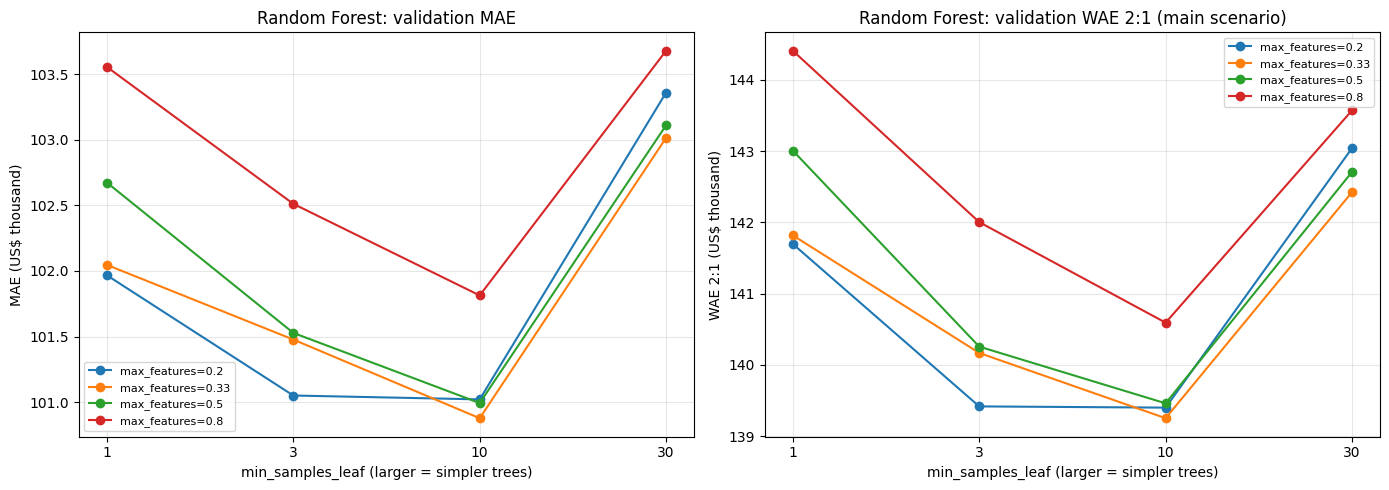

Training, out-of-bag and validation MAE (US$):
run_id                                            configuration  train_MAE  OOB_MAE  validation_MAE  validation_minus_OOB
  R001   n_estimators=200, max_features=0.2, min_samples_leaf=1     35,111   95,388         101,967                 6,579
  R002   n_estimators=200, max_features=0.2, min_samples_leaf=3     51,429   94,327         101,051                 6,724
  R003  n_estimators=200, max_features=0.2, min_samples_leaf=10     75,063   94,269         101,021                 6,752
  R004  n_estimators=200, max_features=0.2, min_samples_leaf=30     88,772   96,657         103,359                 6,702
  R005  n_estimators=200, max_features=0.33, min_samples_leaf=1     35,130   95,437         102,046                 6,610
  R006  n_estimators=200, max_features=0.33, min_samples_leaf=3     49,176   94,385         101,477                 7,092
  R007 n_estimators=200, max_features=0.33, min_samples_leaf=10     73,166   94,085         100,878

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for max_features in RF_GRID["max_features"]:
    subset = rf_results.loc[rf_results["max_features"] == max_features].sort_values("min_samples_leaf")
    leaf_labels = subset["min_samples_leaf"].astype(int).astype(str)
    axes[0].plot(leaf_labels, subset["MAE"] / 1e3, marker="o", label=f"max_features={max_features}")
    axes[1].plot(leaf_labels, subset["WAE_2_1"] / 1e3, marker="o", label=f"max_features={max_features}")
axes[0].set_title("Random Forest: validation MAE")
axes[0].set_ylabel("MAE (US$ thousand)")
axes[1].set_title("Random Forest: validation WAE 2:1 (main scenario)")
axes[1].set_ylabel("WAE 2:1 (US$ thousand)")
for axis in axes:
    axis.set_xlabel("min_samples_leaf (larger = simpler trees)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T3_rf_complexity_grid.png", dpi=150, bbox_inches="tight")
plt.show()

gap_table = rf_results[["run_id", "configuration", "train_MAE", "OOB_MAE", "MAE"]].rename(
    columns={"MAE": "validation_MAE"}
)
gap_table["validation_minus_OOB"] = gap_table["validation_MAE"] - gap_table["OOB_MAE"]
print("Training, out-of-bag and validation MAE (US$):")
print(gap_table.to_string(index=False, float_format=lambda v: f"{v:,.0f}"))

## 6. Scenario-specific selection and the unified results table

Following the group convention, each model family is selected separately under each WAE scenario. The winner table uses the same columns and scenario labels as `data/result/linear_models/scenario_validation_winners.csv`. The pre-specified main scenario is WAE 2:1; the other two are sensitivity results.

In [10]:
all_runs = pd.DataFrame(run_rows)
all_runs.to_csv(OUT_DIR / "tree_validation_results_all_runs.csv", index=False)

winner_rows = []
for family in ["Decision Tree", "Random Forest"]:
    family_runs = all_runs.loc[all_runs["model_family"] == family]
    for metric, (scenario_name, _, _) in SCENARIOS.items():
        best = family_runs.loc[family_runs[metric].idxmin()]
        winner_rows.append({
            "model_family": family,
            "scenario": scenario_name,
            "winning_configuration": best["configuration"],
            "feature_set": best["feature_set"],
            "selected_WAE": best[metric],
            "MSE": best["MSE"],
            "R2": best["R2"],
            "MAE": best["MAE"],
            "run_id": best["run_id"],
        })
scenario_winners = pd.DataFrame(winner_rows)
scenario_winners.drop(columns="run_id").to_csv(OUT_DIR / "tree_scenario_validation_winners.csv", index=False)
print(scenario_winners.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

# Read-only preview next to the linear-model winners (feature sets differ; see the notes in the report).
linear_winners_path = DATA_DIR / "result" / "linear_models" / "scenario_validation_winners.csv"
if linear_winners_path.exists():
    linear_winners = pd.read_csv(linear_winners_path)
    preview = pd.concat(
        [linear_winners[["model_family", "scenario", "winning_configuration", "feature_set", "selected_WAE", "MAE", "R2"]],
         scenario_winners[["model_family", "scenario", "winning_configuration", "feature_set", "selected_WAE", "MAE", "R2"]]],
        ignore_index=True,
    )
    print("\nPreview across families, main scenario only:")
    print(preview.loc[preview["scenario"] == SCENARIOS[MAIN_METRIC][0]]
          .sort_values("selected_WAE").to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

 model_family                                    scenario                                    winning_configuration                         feature_set  selected_WAE                 MSE     R2          MAE run_id
Decision Tree         Main - Overvaluation Priority (2:1)                        max_depth=10, min_samples_leaf=10 Official split CSV (208 predictors)  160,666.5628 58,679,607,837.9868 0.6923 115,419.3784   T018
Decision Tree          Alternative - Equal Priority (1:1)                        max_depth=10, min_samples_leaf=10 Official split CSV (208 predictors)  115,419.3784 58,679,607,837.9868 0.6923 115,419.3784   T018
Decision Tree Alternative - Undervaluation Priority (1:2)                        max_depth=10, min_samples_leaf=50 Official split CSV (208 predictors)  185,207.7171 61,913,610,131.4685 0.6754 115,648.0883   T019
Random Forest         Main - Overvaluation Priority (2:1) n_estimators=200, max_features=0.33, min_samples_leaf=10 Official split CSV (208 predictors)  

### Fixed-prediction comparison under all three scenarios

For the configuration selected under the main 2:1 scenario, predictions are held fixed and scored under all three weightings against the Global Mean baseline (the format required for 4c).

In [11]:
main_winners = scenario_winners.loc[scenario_winners["scenario"] == SCENARIOS[MAIN_METRIC][0]]
fixed_rows = []
for _, winner in main_winners.iterrows():
    model_pred = validation_predictions[winner["run_id"]]
    for metric, (scenario_name, over_w, under_w) in SCENARIOS.items():
        model_wae = weighted_absolute_error(y_val, model_pred, over_w, under_w)
        baseline_wae = weighted_absolute_error(y_val, baseline_prediction, over_w, under_w)
        fixed_rows.append({
            "scenario": scenario_name,
            "model_family": winner["model_family"],
            "feature_set": winner["feature_set"],
            "configuration": winner["winning_configuration"],
            "model_WAE": model_wae,
            "baseline_WAE": baseline_wae,
            "reduction_percent": 100 * (1 - model_wae / baseline_wae),
        })
fixed_comparison = pd.DataFrame(fixed_rows)
fixed_comparison.to_csv(OUT_DIR / "tree_selected_model_fixed_scenario_comparison.csv", index=False)
print(fixed_comparison.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

# Validation predictions of every scenario winner, keyed by transaction for later merging.
prediction_export = val_ids[["transaction_id", "property_id", "sale_date"]].copy()
prediction_export["actual_sale_price"] = y_val
for run_id in scenario_winners["run_id"].unique():
    prediction_export[f"pred_{run_id}"] = validation_predictions[run_id]
prediction_export.to_csv(OUT_DIR / "tree_validation_predictions.csv", index=False)
print("\nSaved scenario winners, fixed-scenario comparison and validation predictions to", OUT_DIR)

                                   scenario  model_family                         feature_set                                            configuration  model_WAE  baseline_WAE  reduction_percent
        Main - Overvaluation Priority (2:1) Decision Tree Official split CSV (208 predictors)                        max_depth=10, min_samples_leaf=10 160,666.56    342,381.82              53.07
         Alternative - Equal Priority (1:1) Decision Tree Official split CSV (208 predictors)                        max_depth=10, min_samples_leaf=10 115,419.38    238,599.62              51.63
Alternative - Undervaluation Priority (1:2) Decision Tree Official split CSV (208 predictors)                        max_depth=10, min_samples_leaf=10 185,591.57    373,417.03              50.30
        Main - Overvaluation Priority (2:1) Random Forest Official split CSV (208 predictors) n_estimators=200, max_features=0.33, min_samples_leaf=10 139,251.86    342,381.82              59.33
         Alternative - Eq

## 7. Validation diagnostics for the main-scenario Random Forest

The selected forest is refitted once (same seed, identical predictions) to inspect feature importance and the structure of its errors. These diagnostics use validation data only and prepare the arguments for 4a and 4b; the final numbers in 4a must come from the frozen model on the 2025 test set.

Selected Random Forest (WAE 2:1): n_estimators=200, max_features=0.33, min_samples_leaf=10
                                            impurity_importance  permutation_MAE_increase  permutation_std
char_bldg_sf                                             0.1236               30,380.3878         524.6669
meta_nbhd_code_te                                        0.0710               10,647.4597         357.0281
inter_log1p_land_bldg_product                            0.0333                5,896.3082         188.4636
loc_property_zip_te                                      0.1234                3,888.2519          30.3646
loc_school_secondary_district_geoid_te                   0.1149                3,879.9665          66.5551
char_fbath                                               0.0439                3,204.1469         231.1643
acs5_median_household_owner_occupied_value               0.0925                2,629.4040         163.8461
char_yrblt                                           

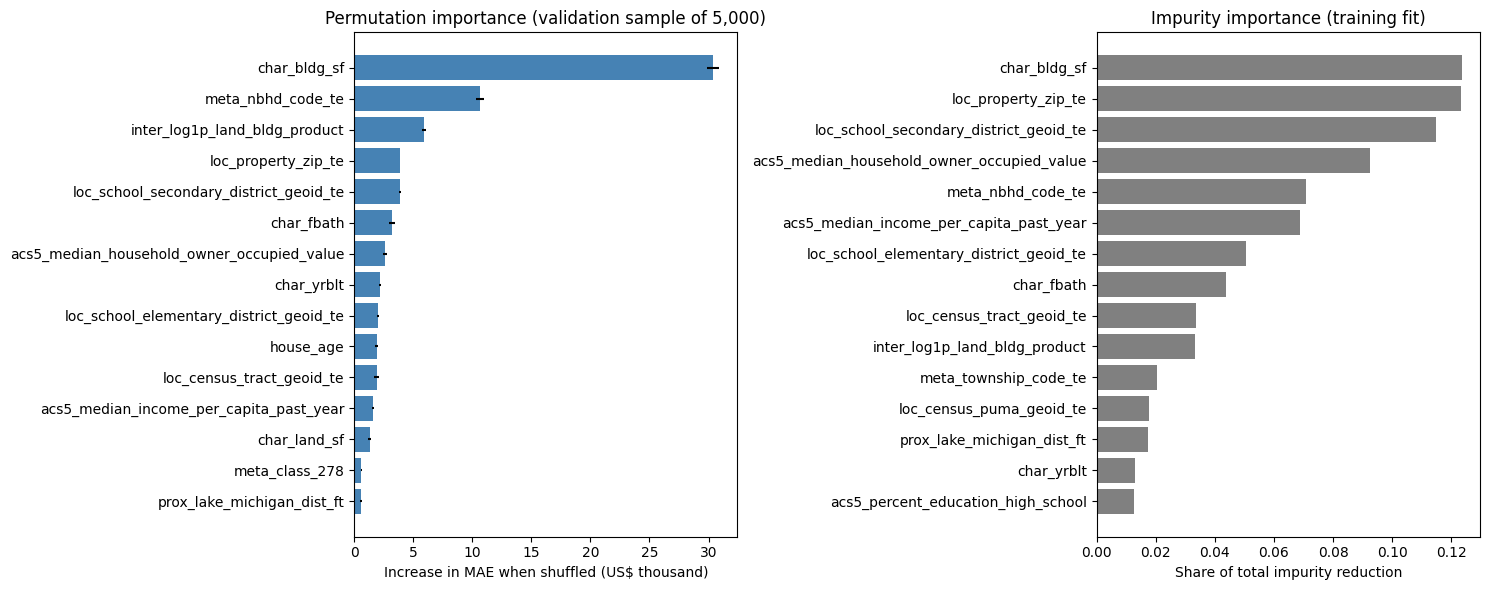

In [12]:
selected_rf = main_winners.loc[main_winners["model_family"] == "Random Forest"].iloc[0]
selected_row = all_runs.loc[all_runs["run_id"] == selected_rf["run_id"]].iloc[0]
SELECTED_RF_PARAMS = {
    "n_estimators": int(selected_row["n_estimators"]),
    "max_features": float(selected_row["max_features"]),
    "min_samples_leaf": int(selected_row["min_samples_leaf"]),
}
print(f"Selected Random Forest (WAE 2:1): {configuration_text(SELECTED_RF_PARAMS)}")

selected_forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **SELECTED_RF_PARAMS)
selected_forest.fit(X_train, y_train_fit)
rf_val_pred = to_dollars(selected_forest.predict(X_val))
assert np.allclose(rf_val_pred, validation_predictions[selected_rf["run_id"]])

impurity = pd.Series(selected_forest.feature_importances_, index=X_train.columns, name="impurity_importance")


def dollar_mae_scorer(estimator, features, target_fit_scale):
    return -mean_absolute_error(to_dollars(target_fit_scale), to_dollars(estimator.predict(features)))


sample_index = val_raw.sample(n=min(PERMUTATION_SAMPLE, len(val_raw)), random_state=RANDOM_STATE).index
permutation = permutation_importance(
    selected_forest,
    X_val.loc[sample_index],
    to_fit_scale(y_val[sample_index]),
    scoring=dollar_mae_scorer,
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = pd.DataFrame({
    "impurity_importance": impurity,
    "permutation_MAE_increase": permutation.importances_mean,
    "permutation_std": permutation.importances_std,
}).sort_values("permutation_MAE_increase", ascending=False)
importance.to_csv(OUT_DIR / "rf_feature_importance.csv", index_label="feature")
print(importance.head(15).to_string(float_format=lambda v: f"{v:,.4f}"))

top = importance.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top.index, top["permutation_MAE_increase"] / 1e3, xerr=top["permutation_std"] / 1e3, color="steelblue")
axes[0].set_title(f"Permutation importance (validation sample of {len(sample_index):,})")
axes[0].set_xlabel("Increase in MAE when shuffled (US$ thousand)")
top_impurity = impurity.sort_values().tail(15)
axes[1].barh(top_impurity.index, top_impurity.values, color="grey")
axes[1].set_title("Impurity importance (training fit)")
axes[1].set_xlabel("Share of total impurity reduction")
plt.tight_layout()
fig.savefig(FIG_DIR / "T4_rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
township_lookup = pd.read_csv(
    DATA_DIR / "properties_2022.csv",
    usecols=["property_id", "meta_township_code"],
    dtype={"property_id": str, "meta_township_code": str},
)
diagnostics = val_ids.merge(township_lookup, on="property_id", how="left", validate="many_to_one")
assert len(diagnostics) == len(val_ids) and diagnostics["meta_township_code"].notna().all()
diagnostics["actual"] = y_val
diagnostics["predicted"] = rf_val_pred
diagnostics["error"] = diagnostics["predicted"] - diagnostics["actual"]
diagnostics["ratio"] = diagnostics["predicted"] / diagnostics["actual"]
diagnostics["abs_pct_error"] = diagnostics["error"].abs() / diagnostics["actual"]
diagnostics["seen_in_training"] = diagnostics["property_id"].isin(set(train_ids["property_id"]))
diagnostics["price_decile"] = pd.qcut(diagnostics["actual"], 10, labels=[f"D{i}" for i in range(1, 11)])
diagnostics["sale_month"] = diagnostics["sale_date"].dt.strftime("%Y-%m")


def group_summary(frame, by):
    grouped = frame.groupby(by, observed=True)
    return pd.DataFrame({
        "sales": grouped.size(),
        "median_price": grouped["actual"].median(),
        "MAE": grouped["error"].apply(lambda e: e.abs().mean()),
        "median_APE": grouped["abs_pct_error"].median(),
        "mean_signed_error": grouped["error"].mean(),
        "median_ratio": grouped["ratio"].median(),
        "share_overvalued": grouped["error"].apply(lambda e: (e > 0).mean()),
    })


overall_ratio = pd.DataFrame({
    "Random Forest": assessment_ratio_statistics(y_val, rf_val_pred),
    "Global Mean": assessment_ratio_statistics(y_val, baseline_prediction),
}).T
print("Assessment-ratio statistics (ratio = estimate / sale price; IAAO guide for single-family: COD 5-15, PRD 0.98-1.03):")
print(overall_ratio.to_string(float_format=lambda v: f"{v:,.3f}"))

by_decile = group_summary(diagnostics, "price_decile")
by_month = group_summary(diagnostics, "sale_month")
by_seen = group_summary(diagnostics, "seen_in_training")
by_township = group_summary(diagnostics, "meta_township_code").sort_values("sales", ascending=False)
for name, table in [("price decile", by_decile), ("sale month", by_month),
                    ("property seen in training", by_seen), ("township (10 largest)", by_township.head(10))]:
    print(f"\nErrors by {name}:")
    print(table.to_string(float_format=lambda v: f"{v:,.3f}"))

by_decile.to_csv(OUT_DIR / "rf_validation_errors_by_price_decile.csv")
by_month.to_csv(OUT_DIR / "rf_validation_errors_by_month.csv")
by_seen.to_csv(OUT_DIR / "rf_validation_errors_by_seen_status.csv")
by_township.to_csv(OUT_DIR / "rf_validation_errors_by_township.csv")
overall_ratio.to_csv(OUT_DIR / "rf_validation_ratio_statistics.csv")

Assessment-ratio statistics (ratio = estimate / sale price; IAAO guide for single-family: COD 5-15, PRD 0.98-1.03):
               median_ratio    COD   PRD
Random Forest         0.950 32.987 1.162
Global Mean           1.199 73.971 1.793

Errors by price decile:
              sales  median_price         MAE  median_APE  mean_signed_error  median_ratio  share_overvalued
price_decile                                                                                                
D1             1822    94,440.000  77,608.273       0.756         75,472.250         1.756             0.935
D2             1807   175,000.000  57,903.027       0.253         28,838.984         1.084             0.577
D3             1824   240,000.000  59,312.932       0.201            711.098         0.961             0.450
D4             1888   285,000.000  59,549.159       0.151         -9,208.380         0.936             0.368
D5             1743   325,000.000  61,374.572       0.142        -18,926.988      

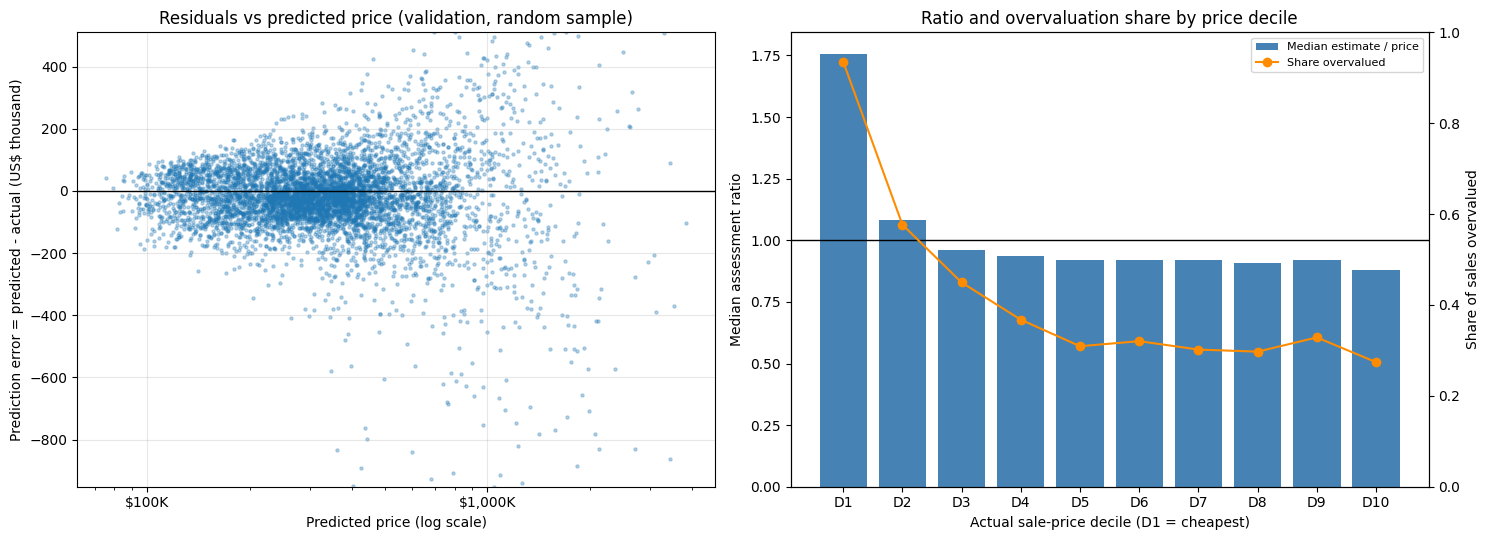

In [14]:
plot_sample = diagnostics.sample(n=min(6000, len(diagnostics)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(plot_sample["predicted"], plot_sample["error"] / 1e3, s=5, alpha=0.3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}K"))
axes[0].set_xlabel("Predicted price (log scale)")
axes[0].set_ylabel("Prediction error = predicted - actual (US$ thousand)")
axes[0].set_title("Residuals vs predicted price (validation, random sample)")
axes[0].set_ylim(np.percentile(plot_sample["error"] / 1e3, [0.5, 99.5]))
axes[0].grid(alpha=0.3)

decile_positions = np.arange(len(by_decile))
axes[1].bar(decile_positions, by_decile["median_ratio"], color="steelblue", label="Median estimate / price")
axes[1].axhline(1, color="black", linewidth=1)
axes[1].set_xticks(decile_positions)
axes[1].set_xticklabels(by_decile.index)
axes[1].set_xlabel("Actual sale-price decile (D1 = cheapest)")
axes[1].set_ylabel("Median assessment ratio")
twin = axes[1].twinx()
twin.plot(decile_positions, by_decile["share_overvalued"], color="darkorange", marker="o", label="Share overvalued")
twin.set_ylabel("Share of sales overvalued")
twin.set_ylim(0, 1)
axes[1].set_title("Ratio and overvaluation share by price decile")
lines = axes[1].get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
labels = axes[1].get_legend_handles_labels()[1] + twin.get_legend_handles_labels()[1]
axes[1].legend(lines, labels, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T5_rf_validation_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Final test evaluation (guarded)

Runs only when `RUN_TEST = True`, after the group has frozen the final model, the target scale, the time-trend decision and the refit window. The routine refits on `FINAL_FIT_WINDOW`, scores the 2025 test set once, refits the Global Mean baseline on the same window, and writes the prediction file in the shared schema used by 4a, 4b and 4c.

Shared test-prediction schema: `transaction_id, property_id, sale_date, meta_township_code, actual_sale_price, predicted_sale_price, model_family, configuration`.

In [15]:
PREDICTION_FILE_COLUMNS = [
    "transaction_id", "property_id", "sale_date", "meta_township_code",
    "actual_sale_price", "predicted_sale_price", "model_family", "configuration",
]


def run_final_test(params):
    test_raw, test_ids = load_split("test")
    X_test = build_features(test_raw, test_ids)
    y_test = test_raw["sale_price"].to_numpy(dtype=float)
    if FINAL_FIT_WINDOW == "train+validation":
        X_fit = pd.concat([X_train, X_val], ignore_index=True)
        y_fit = np.concatenate([y_train, y_val])
        fit_ids = pd.concat([train_ids, val_ids], ignore_index=True)
    else:
        X_fit, y_fit, fit_ids = X_train, y_train, train_ids
    assert X_fit.columns.tolist() == X_test.columns.tolist()

    model = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
    model.fit(X_fit, to_fit_scale(y_fit))
    test_pred = to_dollars(model.predict(X_test))
    baseline_test = np.full(len(y_test), y_fit.mean())

    seen = test_ids["property_id"].isin(set(fit_ids["property_id"]))
    print(f"Refit window: {FINAL_FIT_WINDOW} ({len(y_fit):,} sales); test sales: {len(y_test):,}")
    print(f"Test sales whose property also sold in the refit window: {seen.sum():,} ({seen.mean():.2%})")
    metrics = pd.DataFrame({
        "Random Forest": {**evaluate_regression_predictions(y_test, test_pred), **assessment_ratio_statistics(y_test, test_pred)},
        "Global Mean": {**evaluate_regression_predictions(y_test, baseline_test), **assessment_ratio_statistics(y_test, baseline_test)},
    }).T
    metrics.to_csv(OUT_DIR / "rf_test_metrics.csv")
    print(metrics.to_string(float_format=lambda v: f"{v:,.4f}"))

    output = test_ids.merge(township_lookup, on="property_id", how="left", validate="many_to_one")
    output["actual_sale_price"] = y_test
    output["predicted_sale_price"] = test_pred
    output["model_family"] = "Random Forest"
    output["configuration"] = configuration_text(params)
    output[PREDICTION_FILE_COLUMNS].to_csv(OUT_DIR / "rf_test_predictions.csv", index=False)
    print("Saved rf_test_metrics.csv and rf_test_predictions.csv")
    return output


if RUN_TEST:
    test_output = run_final_test(SELECTED_RF_PARAMS)
else:
    print("RUN_TEST is False: the 2025 test set was not loaded or scored.")

RUN_TEST is False: the 2025 test set was not loaded or scored.


## 9. Output files

In [16]:
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file():
        print(path.as_posix())

data/result/trees/figures/T1_decision_tree_complexity.png
data/result/trees/figures/T2_rf_n_estimators.png
data/result/trees/figures/T3_rf_complexity_grid.png
data/result/trees/figures/T4_rf_feature_importance.png
data/result/trees/figures/T5_rf_validation_residuals.png
data/result/trees/rf_feature_importance.csv
data/result/trees/rf_n_estimators_path.csv
data/result/trees/rf_validation_errors_by_month.csv
data/result/trees/rf_validation_errors_by_price_decile.csv
data/result/trees/rf_validation_errors_by_seen_status.csv
data/result/trees/rf_validation_errors_by_township.csv
data/result/trees/rf_validation_ratio_statistics.csv
data/result/trees/tree_scenario_validation_winners.csv
data/result/trees/tree_selected_model_fixed_scenario_comparison.csv
data/result/trees/tree_validation_predictions.csv
data/result/trees/tree_validation_results_all_runs.csv
